
TUTORIAL: From SMILES to a multicomponent lipid vesicle (with Gromacs)
======================================================================
---
If necessary, follow the Shapespyer installation instructions: https://simnavi.gitlab.io/shapespyer.io/installation.html

Shapespyer repository: https://gitlab.com/simnavi/shapespyer/

Shapespyer documentation: https://simnavi.gitlab.io/shapespyer.io/

### **Overview**

This tutorial is based on several shorter tutorials from the Shapespyer guide supported by `examples` in the repository:

`examples/DLF2GMX_DPPC`, 

`examples/GMX_DPPC_Tails` 

`examples/GMX_LIPS_VES`.

Starting from the bare SMILES strings of three phospholipids, **DOPC**, **DPPC** and **POPC**, we will build a vesicle in which these lipids are mixed with **cholesterol** (CHL) and the two leaflets (monolayers) have *different* compositions:

| leaflet | DOPC | DPPC | POPC | CHL |
|---------|-----:|-----:|-----:|----:|
| inner   | 20 % | 40 % | 30 % | 10 % |
| outer   | 30 % | 10 % | 40 % | 20 % |

The tutorial workflow demonstrates the following stages:

1. **SMILES &rarr; 3D**: generate a `.gro` (and `.pdb`) seed configuration for each phospholipid with the `smiles` tool;
   
2. **3D &rarr; topology**: generate a Gromacs topology (`.itp`) for each lipid with DL_FIELD (see also `examples/DLF2GMX_DPPC`);

3. **Aligning the tails**: run a short restrained simulation for each lipid, so its two hydrocarbon tails are brought together (see also `examples/GMX_DPPC_Tails`);

4. **Vesicle**: place the aligned lipids and cholesterol into a two-leaflet vesicle with the `shape` tool (see also `examples/GMX_POPC-CHOL_Mix` and `examples/GMX_LIPS_VES`).

5. **Vesicle equilibration**: staged Gromacs MD simulation workflow for relatively short restrained equilibration of the vesicle structure created at stage 4.

6. **Trajectory analyses**: density and cluster analysis for the three latest eqilibration stages using `ana-trajectory` tool.

### What can be run where

* **Stages 1 and 4** only need Shapespyer, so all their cells can be executed in this notebook.
  
* **Stages 2 and 3** need external software: DL_FIELD (https://www.ccp5.ac.uk/dl_field/) and Gromacs (https://www.gromacs.org/). **NOTE:** These stages will be presented without commands being executed! For stage 3, one could run MD simulations provided Gromacs is installed. The corresponding commands are given in **text blocks** to be run in a terminal, *not* in this notebook.

* **Stages 5 and 6** require Gromacs installation and serious computer resources (at least 16 CPU cores and 8 Gb of RAM).

* Everything the notebook generates goes into `usr-out/` (please do not overwrite the contents of `inp/`).

### Directory contents

`inp/lipids.sml` - SMILES strings for DPPC, DOPC and POPC.

`inp/lipid_tail_restraints.py` - helper script that adds the tail-alignment restraints to a lipid topology (see stage 3).

`toppar/` - contains all the topology and simulation setup files necessary for this tutorial

**NOTE:** To validate user's generated outputs produced in this tutorial, unpack the archive (this is a *requirement* for this tutorial!):

`tar -xvJf usr-ref.tar.xz`

The above command will create the following structure of subfolders:

`usr-ref/` - contains reference data for user to be able to compare and validate their results.

`usr-ref/smiles/` - reference outputs of `smiles` runs for lipids

`usr-ref/dlf/` - reference data obtained with DL_FIELD

`usr-ref/restraints/` - reference data for restraining lipid tails

`usr-ref/tails/` - reference data obtained upon running Gromacs with restraints for aligning lipid tails

`usr-ref/vesicle/` - reference data obtained upon running Gromacs equilibration stages for a vesicle

**NOTE:** Working through this notebook we will create `usr-out/` which will contain all the user produced artifacts, so the reference outputs in `usr-ref/` are intact!

`usr-out/` - will contain the same subfolder structure as that found in `usr-ref/`.



In [1]:
import glob
import os

import numpy as np

# the lipid library of Shapespyer: <LIPID>/<LIPID>_aligned.gro, <LIPID>/<LIPID>_DLF.itp, ...
# ASSETS = '../../assets/components/lipids'
ASSETS = './inp/assets'

def read_gro(fname):
    """Return atom names, residue names, coordinates and box dimensions in nm."""
    lines = open(fname).read().splitlines()
    n = int(lines[1])
    atoms = lines[2:2 + n]
    names = [line[10:15].strip() for line in atoms]
    resnames = [line[5:10].strip() for line in atoms]
    xyz = np.array([[float(line[20 + 8 * k:28 + 8 * k]) for k in range(3)] for line in atoms])
    box = np.array([float(value) for value in lines[2 + n].split()])
    return names, resnames, xyz, box


def read_pdb(fname):
    """Return atom names, residue names, coordinates and optional box dimensions in nm."""
    lines = open(fname).read().splitlines()
    atoms = [line for line in lines if line.startswith(('ATOM  ', 'HETATM'))]
    names = [line[12:16].strip() for line in atoms]
    resnames = [line[17:21].strip() for line in atoms]
    xyz = np.array([[float(line[30 + 8 * k:38 + 8 * k]) / 10 for k in range(3)] for line in atoms])
    cryst = next((line for line in lines if line.startswith('CRYST1')), None)
    box = None if cryst is None else np.array([float(value) / 10 for value in cryst[6:33].split()])
    return names, resnames, xyz, box


!mkdir -p usr-out/smiles
!ls inp inp/assets

inp:
assets	dl_field.control_temp  lipids.sml  lipid_tail_restraints.py

inp/assets:
CHL.gro  DOPC_aligned.gro  DPPC_aligned.gro  POPC_aligned.gro
CHL.itp  DOPC_DLF.itp	   DPPC_DLF.itp      POPC_DLF.itp


## 1. 3D configurations from SMILES strings
---

A SMILES string encodes the chemical structure of a molecule as a text (in ASCII format). The Shapespyer package provides `smiles` tool that converts a SMILES record into an *idealised* 3D structure (where hydrogens are added automatically), which can be used as a *seed* (template) when preparing a molecular system for simulation: the overall structure gets relaxed during the energy minimisation and equilibration stages, as shown below.

The SMILES strings for our three lipids are collected in `inp/lipids.sml` (cholesterol is not present in the file, and we will use its 3D structure provided in the assets).

In [2]:
!cat inp/lipids.sml

# SMILES for the phospholipids used in the tutorial: DPPC, DOPC and POPC
#
# NOTE: no hydrogens nor stereo-descriptors are present in  SMILES below! By default, hydrogens are added automatically. 
# One can use '--dbcis C' oprion of 'smiles' tool to obtain cis-arrangments around double bonds involving C atoms.
# Otherwise (if the tool is used without this option), the hydrocarbon tails will be generated in all-trans configuration.
#
C40H80NO8P DPPCC CCCCCCCCCCCCCCCC(=O)OCC(COP([O-])(=O)OCC[N+](C)(C)C)OC(=O)CCCCCCCCCCCCCCC
C40H80NO8P DPPC [N+](C)(C)(C)CCOP([O-])(=O)OCC(COC(=O)CCCCCCCCCCCCCCC)OC(=O)CCCCCCCCCCCCCCC
#
C44H84NO8P DOPCC CCCCCCCCC=CCCCCCCCC(=O)OCC(COP([O-])(=O)OCC[N+](C)(C)C)OC(=O)CCCCCCCC=CCCCCCCCC
C44H84NO8P DOPC [N+](C)(C)(C)CCOP([O-])(=O)OCC(COC(=O)CCCCCCCC=CCCCCCCCC)OC(=O)CCCCCCCC=CCCCCCCCC
#
C42H82NO8P POPCC CCCCCCCCCCCCCCCC(=O)OCC(COP([O-])(=O)OCC[N+](C)(C)C)OC(=O)CCCCCCCC=CCCCCCCCC
C42H82NO8P POPC [N+](C)(C)(C)CCOP([O-])(=O)OCC(COC(=O)CCCCCCCCCCCCCCC)OC(=O)CCCCCCCC=CC

**NOTE:** Each record has the following format.

~~~
C40H80NO8P   DPPC   CCCCCCCCCCCCCCCC(=O)OCC(COP(=O)([O-])OCC[N+](C)(C)C)OC(=O)CCCCCCCCCCCCCCC
^^^^^^^^^^   ^^^^   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
chem.f.      name   SMILES string
~~~

**NOTE:** The first two lines in an `.sml` file are preserved for a (commented-out) HEADER, i.e. not read as SMILES records. The list of records ends with the `Box` record. A specific SMILES record can be selected by the molecule's mnemonic name or by its chemical formula (option `-r` of `smiles` tool). In the latter case, if more than one record is found for a particular chemical formula, *all* the respective records will be used for generating individual 3D structures that will be stored in a single structure file.

**NOTE:** All three *canonical* SMILES strings (DPPCC, DOPCC, POPCC) start from one of the *hydrocarbon tails*. That is, when using canonical SMILES, the first atom in the 3D structure of a lipid will be a terminal C-atom, which is at odds with a convention commonly used by simulation community: to order atoms starting from the head-group.

**NOTE:** The topologies (defining the atom order and conncetivity) found in the assets library (as well as the default *bone* vectors defined by `shape` tool, see Stage 4) assume that the atom list starts with the first atom on the head group (N atom for these lipids). 

**Never assume that files for the same molecule generated in different ways have the same atom order** - see below.

Let us generate the 3D structures for our lipids based on their canonical SMILES first. The structures will be stored in `.gro` files (Gromacs configuration format):

In [3]:
!smiles -i lipids.sml -d inp,usr-out/smiles -o DPPCC_smiles.gro -r DPPCC > usr-out/smiles/smiles.log
!smiles -i lipids.sml -d inp,usr-out/smiles -o DOPCC_smiles.gro -r DOPCC --dbcis C >> usr-out/smiles/smiles.log
!smiles -i lipids.sml -d inp,usr-out/smiles -o POPCC_smiles.gro -r POPCC --dbcis C >> usr-out/smiles/smiles.log
!ls usr-out/smiles/*.gro

usr-out/smiles/DOPCC_smiles.gro  usr-out/smiles/POPCC_smiles.gro
usr-out/smiles/DPPCC_smiles.gro


**NOTE:** The generated molecular structures have *idealised* chemical geometry! 

For canonical SMILES (DPPCC, DOPCC, POPCC) we get the tails stretched away from each other - check it in the NGLView below.

In [4]:
import numpy as np
import nglview as nv
from nglview import NGLWidget
from nglview.datafiles import GRO
# layout control
from ipywidgets import Layout, Box

print("Using NGLView version",nv.__version__)

# save the box_layout for all visualisations
# box_layout = Layout(display='flex',
#                     flex_flow='column',
#                     width='100%') 

view = nv.show_structure_file('usr-out/smiles/DPPCC_smiles.gro', gui=True)
#view = nv.show_structure_file('usr-out/smiles/DOPCC_smiles.gro', gui=True)
#view = nv.show_structure_file('usr-out/smiles/POPCC_smiles.gro', gui=True)

# uncomment next line if the GUI menus don't pop up!
#view.gui_style = "NGL"

#view.control.spin([0, 0, 1], np.pi)
#view.control.spin([0, 0.7071, 0.7071], np.pi)
view

Using NGLView version 4.0


NGLWidget()

**NOTE:** For packing molecules into a vesicle we need them aligned next to each other (see Stage 3). 

**NOTE:** To make things easier for aligning lipid tails, we'd better use SMILES starting from the head-group, i.e. N-atom.

Later (see Stage 2) we will learn how to use DL_FIELD software to reorder atoms in a structure to comply with CHARM36 topology convention. DL_FIELD takes a `.pdb` (or `.xyz`) file as input, so now we will generate PDB structures, but will use *non-standard* SMILES starting with N-atoms on the lipid head-groups!

In [5]:
!smiles -i lipids.sml -d inp,usr-out/smiles -o DPPC_smiles.pdb -r DPPC >> usr-out/smiles/smiles.log
!smiles -i lipids.sml -d inp,usr-out/smiles -o DOPC_smiles.pdb -r DOPC --dbcis C >> usr-out/smiles/smiles.log
!smiles -i lipids.sml -d inp,usr-out/smiles -o POPC_smiles.pdb -r POPC --dbcis C >> usr-out/smiles/smiles.log
!ls usr-out/smiles/*.pdb

usr-out/smiles/DOPC_smiles.pdb	usr-out/smiles/POPC_smiles.pdb
usr-out/smiles/DPPC_smiles.pdb


In [6]:
view = nv.show_structure_file('usr-out/smiles/DPPC_smiles.pdb', gui=True)
#view = nv.show_structure_file('usr-out/smiles/DOPC_smiles.pdb', gui=True)
#view = nv.show_structure_file('usr-out/smiles/POPC_smiles.pdb', gui=True)

#view.control.spin([0, 0, 1], np.pi)
#view.control.spin([0, 0.7071, 0.7071], np.pi)
view

NGLWidget()

Let us now check the generated structures: the numbers of atoms (expected: 130 for DPPC, 138 for DOPC and 134 for POPC), the first atom, and the torsion angle about each `C=C` bond, found from the geometry (0 degrees means *cis*, 180 degrees means *trans*).

In [7]:
def torsion(p0, p1, p2, p3):
    """Torsion angle (degrees) for four points."""
    b0, b1, b2 = p0 - p1, p2 - p1, p3 - p2
    b1 = b1 / np.linalg.norm(b1)
    v, w = b0 - np.dot(b0, b1) * b1, b2 - np.dot(b2, b1) * b1
    return np.degrees(np.arctan2(np.dot(np.cross(b1, v), w), np.dot(v, w)))

def double_bond_torsions(fname):
    """Torsions about C=C bonds, i.e. pairs of heavy atoms closer than 0.15 nm."""
    CUTOFF = 0.15 # nm
    reader = read_pdb if fname.lower().endswith('.pdb') else read_gro
    names, _, xyz, _ = reader(fname)
    heavy = [i for i, name in enumerate(names) if not name.startswith('H')]
    near = {i: [j for j in heavy if j != i and np.linalg.norm(xyz[i] - xyz[j]) < 0.16] for i in heavy}
    angles = []
    for i in heavy:
        for j in near[i]:
            if i < j and names[i][0] == names[j][0] == 'C' and np.linalg.norm(xyz[i] - xyz[j]) < CUTOFF:
                a = [k for k in near[i] if k != j][0]
                d = [k for k in near[j] if k != i][0]
                angles.append(round(float(torsion(xyz[a], xyz[i], xyz[j], xyz[d])), 1))
    return angles

for lipid in ['DPPC', 'DOPC', 'POPC']:
    fname = f'usr-out/smiles/{lipid}_smiles.pdb'
    names = read_pdb(fname)[0]
    #names = read_gro(fname)[0]
    print(f'{lipid}: {len(names)} atoms, first atom {names[0]}, C=C torsions: {double_bond_torsions(fname)}')

DPPC: 130 atoms, first atom N1, C=C torsions: []
DOPC: 138 atoms, first atom N1, C=C torsions: [0.2, 0.0]
POPC: 134 atoms, first atom N1, C=C torsions: [0.0]


## 2.1 Topologies from DL_FIELD
---

Stage 2 needs the PDB files from Stage 1 and produces the Gromacs topology files (`.itp`) required by Stage 3, which is why it comes here. This is the procedure described in detail in the tutorial `examples/DLF2GMX_DPPC` (see `example-dppc-dlf2gmx.rst` there), which should be consulted first for the prerequisites. In short:

* DL_FIELD is a separate software package (CCP5 website: https://www.ccp5.ac.uk/dl_field/) which has to be obtained and installed by the user. We use its CHARMM36 lipid force field (`charmm36_lipid`);
* the environment variable `DLF` must point to the DL_FIELD installation directory, which has to contain the template `dl_f_path_temp`;
* the template control file `dl_field.control_temp` must be present in the working directory (a copy is provided in `../DLF2GMX_DPPC/inp`). **Do not modify** the lines with `#UWD`/`#CONF` and the records for *periodic condition* and for *position solute at origin* in it;
* the script `dlf2gmx.bsh` (see the other tutorial on where to get it) runs DL_FIELD for one input file at a time and renames the outputs after the given base name.

Run the following commands in a terminal, starting in the folder where this notebook is located. 

**NOTE: this won't work from within the notebook!**

~~~
# Specify the DL_FIELD location (as per your installation):
export DLF=$HOME/dl_f_4.13

# Create a folder where you will be working on converstion PDB -> GRO/ITP/TOP
mkdir -p usr-out/dlf

# Switch to that folder
cd usr-out/dlf

# Copy the PDB structure (configuration) files you want to convert to Gromacs
# Here we are copying the PDB files that were created from SMILES strings earlier
cp ../smiles/*_smiles.pdb ./

# Copy the provided DL_FIELD control file template
cp ../../inp/dl_field.control_temp ./

# Run dlf2gmx.bsh script for each lipid in our set
for L in DPPC DOPC POPC; do dlf2gmx.bsh ${L}_smiles.pdb ${L}_dlf ${L}; done

# Check the output files
ls -l dlf_output*/*_dlf.*

# switch back to where you started
cd ../..
~~~

Every run of DL_FIELD creates a new output directory (`dlf_output1`, `dlf_output2`, ...), each containing `<L>_dlf.gro`, `<L>_dlf.itp`, `<L>_dlf.top` and `<L>_dlf.mdp`. We need `.gro` and `.itp`, which come as a **matching pair**: the atom order and the atom names in the `.gro` file are those that the `.itp` file refers to.

After sucessfully running `dlf2gmx.bsh` for each lipid, make sure each `.itp` file produced contains:

* the molecule name (not a number!) under `[ moleculetype ]` the same as the residue name in `[ atoms ]` which must be the lipid (residue) name (e.g. `DOPC`), since Gromacs matches them with the `.gro` file and the `[ molecules ]` list in the corresponding `<L>_dlf.top` file;
* the `[ atoms ]` section has 130, 138 and 134 atoms for DPPC, DOPC and POPC, respectively.


In [8]:
# Copy `dlf` folder with the DL_FIELD outputs from the refernece:
%cp -rf usr-ref/dlf usr-out/

!ls usr-out/dlf/dlf_output*

usr-out/dlf/dlf_output1:
dl_field.output      DPPC_dlf.gro  DPPC_dlf.mdp
dlf_notation.output  DPPC_dlf.itp  DPPC_dlf.top

usr-out/dlf/dlf_output2:
dl_field.output      DOPC_dlf.gro  DOPC_dlf.mdp
dlf_notation.output  DOPC_dlf.itp  DOPC_dlf.top

usr-out/dlf/dlf_output3:
dl_field.output      POPC_dlf.gro  POPC_dlf.mdp
dlf_notation.output  POPC_dlf.itp  POPC_dlf.top


In [9]:
!sed -n '9,19p' usr-ref/dlf/dlf_output1/DPPC_dlf.itp

[ moleculetype ]
; name    nrexcl
DPPC      3

[ atoms ]
; nr   type   resnr   residu    atom    cgnr    charge    mass
    1       NTL    1 DPPC       N        1   -0.600000   14.006700
    2      CTL5    1 DPPC     C13        2   -0.350000   12.011000
    3        HL    1 DPPC    H13A        3    0.250000    1.007970
    4        HL    1 DPPC    H13B        4    0.250000    1.007970
    5        HL    1 DPPC    H13C        5    0.250000    1.007970


## 2.2 Assets: topologies and structure templates prepared with the use of DL_FIELD
---

The `.itp` topology files for the lipids above, produced in the same way with DL_FIELD (CHARMM36 lipid force field), are available in the assets library: `assets/components/lipids/<LIPID>/<LIPID>_DLF.itp`, as is `assets/components/lipids/CHL/CHL.itp` for cholesterol. A topology must always be used together with the `.gro` structure file with the same atom order, i.e. for the assets library topologies - with `<LIPID>_aligned.gro` from the same directory.

Similarly, instead of generating the 3D template for a molecule, one can take it from the Shapespyer assets library, `assets/components/lipids/<LIPID>/`, which also provides other lipids (DLPE, DOPE, DPPE, POPE, ...) and cholesterol (`CHL`):

In [10]:
!ls {ASSETS}/*

./inp/assets/CHL.gro	       ./inp/assets/DPPC_aligned.gro
./inp/assets/CHL.itp	       ./inp/assets/DPPC_DLF.itp
./inp/assets/DOPC_aligned.gro  ./inp/assets/POPC_aligned.gro
./inp/assets/DOPC_DLF.itp      ./inp/assets/POPC_DLF.itp


**NOTE:** The `<LIPID>_aligned.gro` files in the library are configurations with *already aligned tails* (so they can be used directly in Stage 4), and the atoms ordered and named to match the topology `<LIPID>_DLF.itp` from the same directory (following the CHARM36 convention). They do **not necessarily match** the atom order in the files generated based on SMILES input above.

**NOTE:** For convenience, copies of the asset files necessary for this tutorial can also be found in `inp/assets`!

In [11]:
print('assets topology (DPPC_DLF.itp), the first few atoms:')
#!head -n 10 {ASSETS}/DPPC/DPPC_DLF.itp
!sed -n '14,24p' {ASSETS}/DPPC_DLF.itp
!echo
print('DL_FIELD processed configuration (DPPC_DLF.gro), the first few atoms:')
!head -n 10 {ASSETS}/DPPC_aligned.gro
!echo
print('configuration generated from canonical SMILES (DPPC_smiles.gro), the first few atoms:')
!head -n 10 usr-out/smiles/DPPCC_smiles.gro
#!sed -n '3,6p' usr-out/smiles/DPPC_smiles.gro

assets topology (DPPC_DLF.itp), the first few atoms:
; nr   type   resnr   residu    atom    cgnr    charge    mass
    1      NTL    1 DPPC    N     1  -0.6000000   14.0067
    2     CTL5    1 DPPC  C13     2  -0.3500000   12.0110
    3       HL    1 DPPC H13A     3   0.2500000    1.0080
    4       HL    1 DPPC H13B     4   0.2500000    1.0080
    5       HL    1 DPPC H13C     5   0.2500000    1.0080
    6     CTL5    1 DPPC  C14     6  -0.3500000   12.0110
    7       HL    1 DPPC H14A     7   0.2500000    1.0080
    8       HL    1 DPPC H14B     8   0.2500000    1.0080
    9       HL    1 DPPC H14C     9   0.2500000    1.0080
   10     CTL5    1 DPPC  C15    10  -0.3500000   12.0110

DL_FIELD processed configuration (DPPC_DLF.gro), the first few atoms:
Control file title. For DL_FIELD 4.11 , t= 0.0
 130    
    1DPPC     N    1   5.000   5.000   8.038
    1DPPC   C13    2   5.146   5.006   8.018
    1DPPC  H13A    3   5.168   5.004   7.911
    1DPPC  H13B    4   5.192   4.920   8.0

**NOTE:** The atom types in the topologies of these lipids (including the alkene types `CEL1` and `HEL1` for the `C=C` bond in DOPC and POPC) have to be defined in the force-field file included before them. Below we use `forcefield.itp` from `examples/GMX_LIPS_VES/toppar`, which defines the types for all three lipids and cholesterol. Do **not** use the one in `examples/GMX_DPPC_Tails/toppar`: it is limited to DPPC and does not contain these alkene types.

In [12]:
view = nv.show_structure_file('./inp/assets/DPPC_aligned.gro', gui=True)
#view = nv.show_structure_file('usr-out/smiles/DOPC_smiles.pdb', gui=True)
#view = nv.show_structure_file('usr-out/smiles/POPC_smiles.pdb', gui=True)

#view.control.spin([0, 0, 1], np.pi)
view.control.spin([0.35, 0.7071, 0.7071], np.pi)
view

NGLWidget()

## 3. Aligning the lipid tails
---

For building a vesicle (or a bilayer), a lipid template in which the two hydrocarbon tails are brought together and aligned with each other is much better than the stretched out one that we got from the SMILES string. The procedure was developed for DPPC in `examples/GMX_DPPC_Tails`: a short simulation of a *single* lipid in water, with additional restraints between selected atom pairs of the lipid that pull the tails together. Here we do the same for all three phospholipids.

![DPPC tails](./_images/DPPC_tails.png)

Below we describe a straightforward *restraining* procedure that can be used for bringing lipid tails together in a relatively short Gromacs simulation for a single (template) lipid molecule.

### Bond-like distance restraints

In `examples/GMX_DPPC_Tails/toppar/DPPC_PRB.itp` the restraints are 6 extra lines at the end of the `[ bonds ]` section:

~~~
;[ distance restraints ]
      1     84   10     2.4  2.6  1000.00  1000.00  ; N - C216
      1    127   10     2.4  2.6  1000.00  1000.00  ; N - C316
     84    127   10     0.4  0.6  1000.00  1000.00  ; C216 - C316
     78    121   10     0.4  0.6  1000.00  1000.00  ; C214 - C314
     72    115   10     0.4  0.6  1000.00  1000.00  ; C212 - C312
     66    109   10     0.4  0.6  1000.00  1000.00  ; C210 - C310
~~~

**NOTE:** The line `;[ distance restraints ]` is commented out in that file, so these lines stay a part of the `[ bonds ]` section. As the interaction type `10` there indicates, they are bonded interactions of the *restraint potential* kind: for a pair of atoms `i j 10 low up1 up2 k` there is no force between the distances `low` and `up1` (in nm), a harmonic force with the force constant `k` (in kJ/mol/nm^2) acts outside of this range, and a linear one beyond `up2`. We keep this convention (and do not use the separate Gromacs `[ distance_restraints ]` section).

The atom indices above refer to the atoms of DPPC, so they can be neither used for DOPC and POPC (which have a different number of atoms in their tails, and also `C=C` bonds), nor for the DL_FIELD topology of the generated DPPC, where the atom order may be different from that in `DPPC_PRB.itp`. Therefore the helper script `inp/lipid_tail_restraints.py` finds the atoms from the *molecular graph* in the `[ bonds ]` section of any (diacyl phospholipid) `.itp` file: the N atom, the two terminal tail C-atoms, and the atoms along each tail counted from its carbonyl C-atom. The restraints are:

| # | atom pair | allowed distance, nm |
|---|-----------|----------------------|
| 1 | N - terminal C of each tail | 2.4 - 2.6 for a tail of 16 C-atoms (as for DPPC), plus 0.125 per extra C-atom: 2.65 - 2.85 for an 18-carbon tail |
| 2 | terminal C - terminal C | 0.4 - 0.6 |
| 3 | pairs of atoms on the two tails at the same position (16, 14, 12 and 10 counted from the carbonyl C), other than that in #2 | 0.4 - 0.6 |

For DPPC this gives exactly the 6 restraints in `DPPC_PRB.itp` shown above, for DOPC and POPC - 7 restraints each. The allowed distance N - terminal C for the 18-carbon tails is extended by analogy with DPPC, following the longer tails of DOPC and POPC (in the library's aligned configurations it is longer by about the same 0.25 nm).

The script is applied to the topology of each lipid from Stage 2; below we run it on the library's topologies (to be able to proceed without DL_FIELD) and look at the result:

In [13]:
!mkdir -p usr-out/restraints
for lipid in ['DPPC', 'DOPC', 'POPC']:
    !python inp/lipid_tail_restraints.py {ASSETS}/{lipid}_DLF.itp usr-out/restraints/{lipid}_PRB.itp
#    !python inp/lipid_tail_restraints.py {ASSETS}/{lipid}/{lipid}_DLF.itp usr-out/restraints/{lipid}_PRB.itp

./inp/assets/DPPC_DLF.itp: tails of 16 and 16 carbons, 6 restraints written to usr-out/restraints/DPPC_PRB.itp
      1     84   10     2.4  2.6  1000.00  1000.00  ; N - C216
      1    127   10     2.4  2.6  1000.00  1000.00  ; N - C316
     84    127   10     0.4  0.6  1000.00  1000.00  ; C216 - C316
     78    121   10     0.4  0.6  1000.00  1000.00  ; C214 - C314
     72    115   10     0.4  0.6  1000.00  1000.00  ; C212 - C312
     66    109   10     0.4  0.6  1000.00  1000.00  ; C210 - C310
./inp/assets/DOPC_DLF.itp: tails of 18 and 18 carbons, 7 restraints written to usr-out/restraints/DOPC_PRB.itp
      1     88   10     2.65  2.85  1000.00  1000.00  ; N - C218
      1    135   10     2.65  2.85  1000.00  1000.00  ; N - C318
     88    135   10     0.4  0.6  1000.00  1000.00  ; C218 - C318
     82    129   10     0.4  0.6  1000.00  1000.00  ; C216 - C316
     76    123   10     0.4  0.6  1000.00  1000.00  ; C214 - C314
     70    117   10     0.4  0.6  1000.00  1000.00  ; C212 -

Note how the same rules apply to atoms of different names and indices in each lipid, and that for POPC (an 18- and a 16-carbon tail) the allowed N - terminal C distance is different for the two tails.

### Short simulations

The simulations follow the lipid tails alignment procedure described in `GMX_DPPC_Tails` tutorial, but for each lipid in its own working directory `usr-out/tails/<L>` (where `<L>` is DPPC, DOPC or POPC). We solvate the lipid in water with `gmx-setup-equil` and then run the four stages with `gmx-equilibrate`: 

- an energy minimisation (`eq0`),
- two short NVT runs (`eq1`, `eq2`)
- an NPT run (`eq3`),

as set-up by the `.mdp` files provided in `GMX_DPPC_Tails/inp`. Those `.mdp` files are not lipid-specific, so we only need to rename them to match the task name (e.g. `DOPC1-wTIP3`) that `gmx-setup-equil` creates from the lipid name and the number of molecules.

**NOTE:** Each seed is placed in the centre of a cubic box with `gmx editconf -c`, because `gmx-setup-equil` solvates the system in the box as given. The box size of 6 nm accommodates the stretched out DOPC and POPC (over 4 nm long) with some margin.

To prepare Gromacs inputs for short restrained MD simulations, run `./seed_lipids.bsh -r 'DPPC,DOPC,POPC'` in the terminal (**not** in the notebook). The script will use the files created at Stage 2 as inputs. If you took the topologies from the assets, you will have to replace `${L}_dlf.itp` and `${L}_dlf.gro` files for `<LIPID>_DLF.itp` and `<LIPID>_aligned.gro` taken from the library (see `ITP` and `GRO` below), in which case the tails are already aligned in the latter, but the procedure can still be rehearsed this way.

If DL_FILED outputs are ready (check with `ls usr-out/dlf/dlf_output*/*dlf.*`), you can run in the terminal (**not** in the notebook!):

`./seed_lipids.bsh -r 'DPPC,DOPC,POPC' ` 

The script does essentially the following:

~~~
EXAMPLES=$(cd .. && pwd)

for L in DPPC DOPC POPC; do
  W=usr-out/tails/$L
  mkdir -p $W/toppar

  # the Stage 2 outputs (the newest ones, if there are several runs)
  ITP=$(ls -t usr-out/dlf/dlf_output*/${L}_dlf.itp | head -1)
  GRO=$(ls -t usr-out/dlf/dlf_output*/${L}_dlf.gro | head -1)

  # topologies: plain (gmx-setup-equil expects it) and restrained (used in the runs)
  cp $ITP $W/toppar/$L.itp
  python inp/lipid_tail_restraints.py $W/toppar/$L.itp $W/toppar/${L}_PRB.itp
  cp $EXAMPLES/GMX_LIPS_VES/toppar/forcefield.itp $EXAMPLES/GMX_LIPS_VES/toppar/TIP3.itp $W/toppar/

  # seed in the centre of the box, then solvate it
  gmx editconf -f $GRO -o $W/${L}_seed.gro -c -box 6 6 6
  ( cd $W
    NATOMS=$(sed -n 2p ${L}_seed.gro | tr -d ' ')
    gmx-setup-equil ${L}_seed.gro $L $NATOMS
    # include the restrained topology instead of the plain one
    sed -i "s|toppar/${L}.itp|toppar/${L}_PRB.itp|" ${L}1-wTIP3.top
    for i in 0 1 2 3; do cp $EXAMPLES/GMX_DPPC_Tails/inp/DPPC1-wTIP3-eq$i.mdp ${L}1-wTIP3-eq$i.mdp; done
    ls
  )
done
~~~

Check that in each `usr-out/tails/<L>` there are the files `<L>1.gro`, `<L>1-wTIP3.gro` and `<L>1-wTIP3.top` (including `toppar/<L>_PRB.itp`), and then run the simulations, one lipid at a time (if needed, check the script help: `gmx-equilibrate -h`):

~~~
cd usr-out/tails/DOPC
gmx-equilibrate DOPC1-wTIP3 0 3 1
~~~

**NOTE:** We had to use a single CPU core here because a single lipid system is too small to justify domain decomposition (you can try asking for more than one core and see it for yourself - it won't work unless you enlarge the system, i.e. box, sufficiently, but then you will have to add much more water molecules)!

The results of the four stages are stored in the subdirectories `eq0`, `eq1`, `eq2` and `eq3` (the trajectories `eq?/<L>1-wTIP3-eq?.xtc` contain plenty of conformations to choose from, see `GMX_DPPC_Tails`).

### Getting the aligned lipid

The solute atoms come first in the `.gro` file, so the lipid can be cut out of the final configuration of the last stage (the box line is the last one in the file):

~~~
L=DOPC
GRO=eq3/${L}1-wTIP3-eq3.gro
N=$(sed -n 2p ${L}_seed.gro | tr -d ' ')
{ echo "$L aligned tails"; echo $N; sed -n "3,$((N+2))p" $GRO; tail -n 1 $GRO; } > ${L}_aligned.gro
~~~

You can repeat the same operations for all lipids:

~~~
for L in DPPC DOPC POPC; do cd usr-out/tails/${L}; GRO=eq3/${L}1-wTIP3-eq3.gro; N=$(sed -n 2p ${L}_seed.gro | tr -d ' '); { echo "$L aligned tails"; echo $N; sed -n "3,$((N+2))p" $GRO; tail -n 1 $GRO; } > ${L}_aligned.gro; cd -; done
~~~

Visualise the result (e.g. with VMD or NGLView) to make sure that the tails are really aligned and the molecule has not been broken across the periodic boundary: in that case, convert the frame with `gmx trjconv -pbc whole` first. A conformation from the trajectory can be chosen instead.

The restraint distances in the chosen configuration can also be compared with the allowed intervals using the cell below (set `restraints` and `gro` to your files; it does nothing if they are not found). The restraints are not rigid, so a distance outside its interval is not an error in itself. For reference, in the aligned configurations from the assets library the distances between the tails are inside the intervals (0.4 - 0.6 nm), whereas the N - terminal C distances (2.9 - 3.2 nm) are larger than the N - C intervals given above.

In [14]:
# Copy `tails` folder with the simulation results from the refernece:
%cp -rf usr-ref/tails usr-out/

def check_restraints(itp, gro):
    """Distances (nm) for the type-10 restraints in an .itp file, in a single-lipid .gro file."""
    names, _, xyz, _ = read_gro(gro)
    for line in open(itp):
        rec = line.split(';')[0].split()
        if len(rec) == 7 and rec[2] == '10':
            i, j, low, up1 = int(rec[0]) - 1, int(rec[1]) - 1, float(rec[3]), float(rec[4])
            dist = np.linalg.norm(xyz[i] - xyz[j])
            flag = 'ok' if low - 0.05 <= dist <= up1 + 0.05 else 'off'
            print(f'{names[i]:>5s} - {names[j]:<5s} {dist:5.2f} nm  (allowed {low:g} - {up1:g})  {flag}')

# restraints = 'usr-out/tails/DOPC/toppar/DOPC_PRB.itp'
# gro = 'usr-out/tails/DOPC/DOPC_aligned.gro'
# if os.path.exists(restraints) and os.path.exists(gro):
#     check_restraints(restraints, gro)
# else:
#     print('Files not found - run the simulation for DOPC (see above) first.')

for LIPID in {'DPPC', 'DOPC', 'POPC'}:
    print(f"\nChecking restrainted structure for {LIPID}:")
    restraints = f'usr-out/tails/{LIPID}/toppar/{LIPID}_PRB.itp'
    gro = f'usr-out/tails/{LIPID}/{LIPID}_aligned.gro'
    if os.path.exists(restraints) and os.path.exists(gro):
        check_restraints(restraints, gro)
    else:
        print('Files not found - run the simulation for {LIPID} (see above) first.')


Checking restrainted structure for DOPC:
    N - C218   2.57 nm  (allowed 2.65 - 2.85)  off
    N - C318   2.59 nm  (allowed 2.65 - 2.85)  off
 C218 - C318   0.44 nm  (allowed 0.4 - 0.6)  ok
 C216 - C316   0.45 nm  (allowed 0.4 - 0.6)  ok
 C214 - C314   0.44 nm  (allowed 0.4 - 0.6)  ok
 C212 - C312   0.47 nm  (allowed 0.4 - 0.6)  ok
 C210 - C310   0.63 nm  (allowed 0.4 - 0.6)  ok

Checking restrainted structure for DPPC:
    N - C216   2.44 nm  (allowed 2.4 - 2.6)  ok
    N - C316   2.51 nm  (allowed 2.4 - 2.6)  ok
 C216 - C316   0.40 nm  (allowed 0.4 - 0.6)  ok
 C214 - C314   0.56 nm  (allowed 0.4 - 0.6)  ok
 C212 - C312   0.58 nm  (allowed 0.4 - 0.6)  ok
 C210 - C310   0.57 nm  (allowed 0.4 - 0.6)  ok

Checking restrainted structure for POPC:
    N - C218   2.71 nm  (allowed 2.65 - 2.85)  ok
    N - C316   2.34 nm  (allowed 2.4 - 2.6)  off
 C218 - C316   0.57 nm  (allowed 0.4 - 0.6)  ok
 C216 - C316   0.53 nm  (allowed 0.4 - 0.6)  ok
 C214 - C314   0.56 nm  (allowed 0.4 - 0.6)  ok
 

## 4. Vesicle with different composition of the two leaflets
---

Now we have the aligned lipids and can build the vesicle with `shape`. The same approach as in the tutorials `GMX_POPC-CHOL_Mix` and `GMX_LIPS_VES` is used (please see the former for the detailed explanation of the 'bone director' of a molecule and of its `mint`/`mext` atoms), extended to four species with different composition of the leaflets.

### The input configuration

The input for `shape` is a single file with one template molecule of each species. We assemble it from the four aligned configurations. By default these are the library ones (for the three phospholipids and, always, for cholesterol); to use the lipids from Stage 3, change the paths accordingly (e.g. `usr-out/tails/DOPC/DOPC_aligned.gro`).

**NOTE:** The order of the species in this file, and in all the options below, is: `DOPC`, `DPPC`, `POPC`, `CHL`.

In [15]:
#!pwd
!mkdir -p usr-out/vesicle

order = ['DOPC', 'DPPC', 'POPC', 'CHL']

# the lipid library of Shapespyer: <LIPID>/<LIPID>_aligned.gro, <LIPID>/<LIPID>_DLF.itp, ...
# ASSETS = '../../assets/components/lipids'
TAILS="usr-out/tails"

seeds = {
    'DOPC': f'{TAILS}/DOPC/DOPC_aligned.gro',
    'DPPC': f'{TAILS}/DPPC/DPPC_aligned.gro',
    'POPC': f'{TAILS}/POPC/POPC_aligned.gro',
    'CHL': f'{ASSETS}/CHL.gro',  # cholesterol is always taken from the library
    # 'DOPC': f'{ASSETS}/DOPC/DOPC_aligned.gro',
    # 'DPPC': f'{ASSETS}/DPPC/DPPC_aligned.gro',
    # 'POPC': f'{ASSETS}/POPC/POPC_aligned.gro',
    # 'CHL': f'{ASSETS}/CHL/CHL.gro',  # cholesterol is always taken from the library
}

def merge_gro(files, fout, title):
    """Put the (single molecule) configurations from the .gro files one after another."""
    body, natoms = [], []
    for fname in files:
        lines = open(fname).read().splitlines()
        natoms.append(int(lines[1]))
        body += lines[2:2 + natoms[-1]]
    out = [title, f'{len(body):5d}']
    out += [line[:15] + f'{i % 100000:5d}' + line[20:] for i, line in enumerate(body, 1)]
    out.append('  10.00000  10.00000  10.00000')
    open(fout, 'w').write('\n'.join(out) + '\n')
    return natoms

natoms = merge_gro([seeds[s] for s in order], 'usr-out/vesicle/DOPC-DPPC-POPC-CHL.gro',
                   'DOPC + DPPC + POPC + CHL template 3D coordinates')
print(dict(zip(order, natoms)))

{'DOPC': 138, 'DPPC': 130, 'POPC': 134, 'CHL': 74}


### The 'bone' atoms

For a vesicle the `mext` ('exterior') atom is, in effect, the head-group atom and the `mint` ('interior') atom is at the tail end. We pick the atoms by name, so the indices (0-based) are correct for whatever atom order the seed files have (only the names have to be those of the CHARMM topologies):

* the phosphorus atom `P` on each phospholipid and the oxygen atom `O3` of the hydroxyl group on cholesterol, for the head groups;
* the terminal C-atom of the (longest) tail on phospholipids: `C218` for DOPC and POPC, `C216` for DPPC, and `C27` at the end of the side chain on cholesterol.

As in `GMX_LIPS_VES`, the head atoms of the species are given in `--mint`, and the tail atoms - in `--mext`, so the radial order of the 'bone' atoms is reversed for the vesicle (the option `--rev` would have the same effect with the usual `mint`/`mext` assignment).

In [16]:
heads = {'DOPC': 'P', 'DPPC': 'P', 'POPC': 'P', 'CHL': 'O3'}
#tails = {'DOPC': 'C218', 'DPPC': 'C216', 'POPC': 'C218', 'CHL': 'C27'}
tails = {'DOPC': 'C318', 'DPPC': 'C316', 'POPC': 'C316', 'CHL': 'C27'}

head_ids = [read_gro(seeds[s])[0].index(heads[s]) for s in order]
tail_ids = [read_gro(seeds[s])[0].index(tails[s]) for s in order]

mint = '[' + ','.join(map(str, head_ids)) + ']'
mext = '[' + ','.join(map(str, tail_ids)) + ']'
print('mint =', mint, ' mext =', mext)

mint = [19,19,19,2]  mext = [134,126,130,70]


### The composition of the leaflets

The fractions of the species are given by `--fracs` as one list per leaflet, in the order of the species, from the **inner** to the **outer** leaflet. The numbers in each list are normalised, so they may be given in percent:

`--fracs=[[20,40,30,10],[30,10,40,20]]`

for the compositions in the table at the top. The number of the leaflets and the scaling factors for the distances and radii in them are given by `--layers`, as in `GMX_LIPS_VES`: `--layers=[2,1.22,0.97]` stands for 2 leaflets, followed by the scaling factors for the minimum distance `--dmin` between the 'bone' atoms (1.22) and for the radius `--rmin` (0.97), as used in `GMX_LIPS_VES`. `--rmin 4.0` sets the inner radius (nm), and `--sbuff 2.0` the solvation buffer (nm).

In [17]:
%cd -q usr-out/vesicle/

!shape -i DOPC-DPPC-POPC-CHL.gro -o config -x .gro -r '[DOPC,DPPC,POPC,CHL]' \
      --mint='{mint}' --mext='{mext}' -s ves --rmin 2.8 --dmin 0.65 --fxz --layers='[2,1.3,0.95]' \
      --sbuff 1.6 --fracs='[[20,40,30,10],[30,10,40,20]]' > shape.log

!ls conf*

config_DOPC-DPPC-POPC-CHL_mi19-19-19-2_mx134-126-130-70_frc20x40x30x10-30x10x40x20_ves_nmr739_ml2x1.3x0.95_cr28A_dm6.5A_fxz_sb16A.gro
config_DOPC-DPPC-POPC-CHL_mi19-19-19-2_mx134-126-130-70_frc20x40x30x10-30x10x40x20_ves_nmr739_ml2x1.3x0.95_cr28A_dm6.5A_fxz_sb16A.gro.inp.yaml
config_DOPC-DPPC-POPC-CHL_mi19-19-19-2_mx134-126-130-70_frc20x40x30x10-30x10x40x20_ves_nmr739_ml2x1.3x0.95_cr28A_dm6.5A_fxz_sb16A.gro.log
config_DOPC-DPPC-POPC-CHL_mi19-19-19-2_mx134-126-130-70_frc20x40x30x10-30x10x40x20_ves_nmr739_ml2x1.3x0.95_cr28A_dm6.5A_fxz_sb16A.gro.yaml


**NOTE:** The output file name reflects the non-default options used, including the fractions (`frc20x40x30x10-30x10x40x20`), and the progress report is in the `.log` file with the same name.

### Checking the result

The fractions are *average* values the vesicle is built with, so let us check the actual composition of each leaflet, as well as the radial positions of the head and the tail atoms for each species and leaflet. The leaflet of a molecule is determined from the distance of its centre to the vesicle centre (the centre of the box).

In [18]:
# vesicle = [f for f in glob.glob('usr-out/vesicle/config_*_ves_*.gro') if 'frc20x40x30x10-30x10x40x20' in f][0]
vesicle = [f for f in glob.glob('config_*_ves_*.gro') if 'frc20x40x30x10-30x10x40x20' in f][0]
names, resnames, xyz, box = read_gro(vesicle)
centre = box[:3] / 2
sizes = dict(zip(order, natoms))

mols = []  # (species, centre-to-centre distance, head radius, tail radius)
start = 0
while start < len(names):
    spec = resnames[start]
    sel = slice(start, start + sizes[spec])
    mnames, mxyz = names[sel], xyz[sel]
    radius = lambda atom: np.linalg.norm(mxyz[mnames.index(atom)] - centre)
    mols.append((spec, np.linalg.norm(mxyz.mean(axis=0) - centre), radius(heads[spec]), radius(tails[spec])))
    start += sizes[spec]

# two leaflets: split at the largest gap between the sorted radial distances of the molecules' centres
dist = np.sort([m[1] for m in mols])
rsplit = (dist[np.argmax(np.diff(dist))] + dist[np.argmax(np.diff(dist)) + 1]) / 2

print(f'{len(mols)} molecules, box {box[0]} nm\n')
for leaflet, inside in [('inner', True), ('outer', False)]:
    lmols = [m for m in mols if (m[1] < rsplit) == inside]
    print(f'{leaflet} leaflet: {len(lmols)} molecules')
    for spec in order:
        smols = [m for m in lmols if m[0] == spec]
        print(f'  {spec}: {len(smols):4d} ({100 * len(smols) / len(lmols):5.1f} %)   '
              f'<r(head)> = {np.mean([m[2] for m in smols]):5.2f} nm   <r(tail end)> = {np.mean([m[3] for m in smols]):5.2f} nm')

# Store the generated initial structure and all the outputs of shape tool for reference
!mkdir -p shape-out
#!pwd

!mv config_*_frc20x40x30x10-30x10x40x20_ves_* shape-out/
!ls ./shape-out/config*gro
#!ls usr-out/vesicle/shape-out/config*


739 molecules, box 18.29829 nm

inner leaflet: 218 molecules
  DOPC:   44 ( 20.2 %)   <r(head)> =  2.78 nm   <r(tail end)> =  5.02 nm
  DPPC:   87 ( 39.9 %)   <r(head)> =  2.86 nm   <r(tail end)> =  5.05 nm
  POPC:   65 ( 29.8 %)   <r(head)> =  3.01 nm   <r(tail end)> =  5.05 nm
  CHL:   22 ( 10.1 %)   <r(head)> =  3.27 nm   <r(tail end)> =  5.03 nm
outer leaflet: 521 molecules
  DOPC:  156 ( 29.9 %)   <r(head)> =  7.83 nm   <r(tail end)> =  5.59 nm
  DPPC:   52 ( 10.0 %)   <r(head)> =  7.77 nm   <r(tail end)> =  5.58 nm
  POPC:  208 ( 39.9 %)   <r(head)> =  7.63 nm   <r(tail end)> =  5.60 nm
  CHL:  105 ( 20.2 %)   <r(head)> =  7.35 nm   <r(tail end)> =  5.59 nm
./shape-out/config_DOPC-DPPC-POPC-CHL_mi19-19-19-2_mx134-126-130-70_frc20x40x30x10-30x10x40x20_ves_nmr739_ml2x1.3x0.95_cr28A_dm6.5A_fxz_sb16A.gro


**NOTE:** The initial vesicle structure we created is too large to be viewed in NGLView, but you can check it in VMD (visualisation software: https://www.ks.uiuc.edu/Research/vmd/).


![Vesicle](./_images/Vesicle_PlaneClip_VMD_VDW_3D.png)
====================


We see the requested compositions in the two leaflets, with the tail ends of all species at the same radius within each leaflet. The phospholipid head groups (P atoms) of DOPC and POPC are on the leaflet surface; those of DPPC are a little farther from it (its tails are shorter). Cholesterol hydroxyl groups (O3) are placed about 1 nm deeper than the P atoms, i.e. the bulky head groups stay on the surface while cholesterol sits in between the tails.

**NOTE:** The two leaflets have different numbers of molecules (the outer one is larger, as it has the larger area), so the overall composition of the vesicle is not the average of the two compositions.

The vesicle can be visualised with VMD (it is too large for NGLView). If the arrangement of any species is not as expected (e.g. a cholesterol sticking out too much), revise the choice of its `mint`/`mext` atoms as explained in `GMX_POPC-CHOL_Mix`.

## 5. Solvation and staged equilibration

The generated vesicle is the starting point for the final preparation and equilibration stage. This follows the procedure in `GMX_LIPS_VES`: assemble the Gromacs inputs and solvate the vesicle, then relax it through a sequence of simulations with progressively weaker flat-bottom restraints. Use the plain `DOPC.itp`, `DPPC.itp` and `POPC.itp` topologies here, **not** the tail-restraint topologies from Stage 3. The completed inputs and outputs for this system are under `usr-out/vesicle/`.

**Run all commands shown below in a separate terminal opened in the `GMX_LIPIDS_WORKFLOW` directory. Do not run the setup or simulation commands as notebook cells.** The Python cells in this section only inspect files that already exist.

### Preparing and solvating the multicomponent system

The `gmx-setup-equil` workflow used for a single solute has a multicomponent counterpart, `gmx-setup-multi`, which is required here because the configuration contains four distinct solute species. Their atom counts are DOPC 138, DPPC 130, POPC 134 and CHL 74. The files required by the setup tool (`forcefield.itp`, the four lipid topologies and `TIP3.itp`) are already collected in `usr-out/vesicle/toppar/`.

In a separate terminal, copy the selected Shapespyer configuration to a short working name and run the setup tool:

~~~bash
cd usr-out/vesicle

cp shape-out/config_*_frc20x40x30x10-30x10x40x20_ves_*.gro DOPC200-DPPC139-POPC273-CHL127.gro
gmx-setup-multi DOPC200-DPPC139-POPC273-CHL127.gro \
  '[DOPC,DPPC,POPC,CHL]' '[138,130,134,74]'
~~~

The setup reads the molecule counts from the configuration, solvates it with TIP3 water and creates the task name `DOPC200-DPPC139-POPC273-CHL127-wTIP3`. The important products are the solvated configuration (`.gro`), topology (`.top`) and index (`.ndx`). The topology records 200 DOPC, 139 DPPC, 273 POPC, 127 CHL and 166753 TIP3 molecules.

The seven prepared simulation parameter files are in `toppar/`. Copy them and the list of restrained species to the working directory before starting the staged run:

~~~bash
TASK=DOPC200-DPPC139-POPC273-CHL127-wTIP3
cp toppar/${TASK}-eq?.mdp .
cp toppar/solutes-posres.txt .
cat solutes-posres.txt
~~~

The last command should print `DOPC|DPPC|POPC|CHL`. This tells `gmx-equilibrate` to generate restraint reference coordinates for every lipid species, rather than only the first species in the configuration.

In [19]:
from pathlib import Path
import re

# Copy `vesicle` reference data (entire simulation setup and outputs from `usr-ref`
# Only in case you don't have time or resources to run actual simulations!
%cp -rf ../../usr-ref/vesicle/* ./

# vesicle_dir = Path('usr-out/vesicle')
vesicle_dir = Path('.')
task = 'DOPC200-DPPC139-POPC273-CHL127-wTIP3'

print(f'{"stage":<6} {"integrator":<12} {"length":>12} {"restraint":>18}')
for stage in range(7):
    mdp = vesicle_dir / 'toppar' / f'{task}-eq{stage}.mdp'
    text = mdp.read_text()
    settings = {}
    for raw_line in text.splitlines():
        line = raw_line.split(';', 1)[0].strip()
        if line and '=' in line:
            key, value = line.split('=', 1)
            settings[key.strip()] = value.strip()
    integrator = settings['integrator']
    if integrator == 'steep':
        length = f'{settings["nsteps"]} steps'
    else:
        length = f'{float(settings["dt"]) * int(settings["nsteps"]):g} ps'
    match = re.search(r'DPOSRES_FC_LIP=([0-9.]+)', settings.get('define', ''))
    restraint = f'     {match.group(1)} kJ mol^-1 nm^-2' if match else 'none'
    print(f'eq{stage:<4} {integrator:<12} {length:>12} {restraint:>18}')

stage  integrator         length          restraint
eq0    steep         10000 steps               none
eq1    md                  25 ps      500.0 kJ mol^-1 nm^-2
eq2    md                  50 ps      300.0 kJ mol^-1 nm^-2
eq3    md                 200 ps      200.0 kJ mol^-1 nm^-2
eq4    md                 500 ps      100.0 kJ mol^-1 nm^-2
eq5    md                1000 ps      50.0 kJ mol^-1 nm^-2
eq6    md               10000 ps      20.0 kJ mol^-1 nm^-2


### Running the seven stages

The table above is read directly from the prepared `.mdp` files. Stage `eq0` performs unrestrained steepest-descent energy minimisation. Stage `eq1` is a short NVT run; `eq2` through `eq6` are NPT runs. The MD timestep increases from 1 fs in `eq1` and `eq2` to 2 fs in the later stages, while the active lipid restraint force constant decreases from 500 to 20 kJ mol⁻¹ nm⁻². The temperature is 320 K, and pressure-coupled stages use 1 bar.

Run all stages in order from a separate terminal. The final argument is the example total thread count; adjust it for the available hardware. The `-nohup` option leaves the long workflow running after the terminal is released.

~~~bash
cd usr-out/vesicle
TASK=DOPC200-DPPC139-POPC273-CHL127-wTIP3
gmx-equilibrate -nohup $TASK 0 6 16
~~~

`gmx-equilibrate` uses the initial solvated `.gro` and `.top` files for `eq0`, then passes the final configuration of each stage to the next one. For restrained stages it also creates a `-posres.gro` reference centred in the current box. On successful completion, the complete inputs, logs, checkpoints, energies, final coordinates and trajectories for each stage are moved into `eq0/`, `eq1/`, ..., `eq6/`. The terminal output is collected in `nohup.out`. These simulations are substantial and can take hours or longer; do not launch them from this notebook.

### Supplied trajectories and reference outputs

To keep the tutorial footprint manageable, the original full trajectories are not included. Stages `eq1`-`eq3` provide trajectories containing every second original frame (`_skip2.xtc`), while `eq4`-`eq6` provide every tenth frame (`_skip10.xtc`). For each stage, the `-wTIP3` trajectory retains water and the `-nowTIP3` trajectory contains only the lipid vesicle. The energy files, stage logs, final configurations and other compact outputs are retained alongside them.

In [20]:
for stage in range(1, 7):
    trajectories = sorted((vesicle_dir / f'eq{stage}').glob('*_skip*.xtc'))
    print(f'eq{stage}:')
    for trajectory in trajectories:
        print(f'  {trajectory.name} ({trajectory.stat().st_size / 1024**2:.1f} MiB)')

eq1:
eq2:
eq3:
eq4:
eq5:
eq6:


**NOTE:** A reference copy of the **entire tutorial workflow** -from the SMILES and DL_FIELD stages through tail alignment, vesicle construction and all seven equilibration stages, is stored under `usr-ref/`. Its directory layout mirrors `usr-out/`, so it can be used to compare expected names and results. **Treat `usr-ref/` as read-only: do not run commands there and do not alter, replace or delete any of its contents.**

## 6. Density and mixed-lipid cluster analysis

The final three equilibration stages can be compared with `ana-trajectory`, following the analysis used in the `GMX_LIPS_VES` tutorial. Here we analyse the supplied water-free, reduced trajectories from `eq4`, `eq5` and `eq6`. The small numbers of retained frames make this a demonstration of the workflow and file formats, not a converged statistical analysis.

`ana-trajectory` reads DCD trajectories, whereas the supplied trajectories are XTC files. The next cell uses MDTraj to read each XTC with its matching GRO topology and write a DCD into that stage's `analysis/` directory. The original XTC and GRO files are not changed. MDTraj also transfers the trajectory coordinates and periodic unit-cell information to the DCD.

All generated material remains with the stage from which it was obtained:

~~~text
eqN/analysis/
  <trajectory>.dcd
  density/
  cluster-all-lipids-dmax1.6-0.8nm/
  figures/
~~~

In [21]:
from pathlib import Path
import mdtraj as md

# The notebook changed into usr-out/vesicle in Section 4.
analysis_root = Path('.')
analysis_system = 'DOPC200-DPPC139-POPC273-CHL127-nowTIP3'

for stage in (4, 5, 6):
    stage_dir = analysis_root / f'eq{stage}'
    analysis_dir = stage_dir / 'analysis'
    analysis_dir.mkdir(exist_ok=True)
    stem = f'{analysis_system}-eq{stage}_skip10'
    xtc = stage_dir / f'{stem}.xtc'
    gro = stage_dir / f'{analysis_system}-eq{stage}.gro'
    dcd = analysis_dir / f'{stem}.dcd'

    if dcd.exists():
        trajectory = md.open(str(dcd))
        print(f'eq{stage}: using {dcd} ({len(trajectory)} frames)')
        trajectory.close()
    else:
        trajectory = md.load(str(xtc), top=str(gro))
        trajectory.save_dcd(str(dcd))
        print(f'eq{stage}: converted {trajectory.n_frames} frames to {dcd}')

eq4: using eq4/analysis/DOPC200-DPPC139-POPC273-CHL127-nowTIP3-eq4_skip10.dcd (6 frames)
eq5: using eq5/analysis/DOPC200-DPPC139-POPC273-CHL127-nowTIP3-eq5_skip10.dcd (11 frames)
eq6: using eq6/analysis/DOPC200-DPPC139-POPC273-CHL127-nowTIP3-eq6_skip10.dcd (11 frames)


### Run `ana-trajectory`

The density calculation requests molecular number density (`nden`), mass density (`mden`) and neutron scattering-length density (`nsld`) on a radial grid from 0 to 12 nm with 0.1 nm spacing. The plots below use the molecular-centre-of-mass number-density tables, the total atom-based mass-density and SLD tables, and the residue-specific atomic mass-density contributions.

For mixed-lipid clustering, 1.6 nm is the cutoff used to identify the vesicle/leaflet environment and 0.8 nm is the lipid-lipid subcluster cutoff, matching the approach in `GMX_LIPS_VES`. The subcluster selection contains all four lipid species: DOPC, DPPC, POPC and CHL. Inner (`int`) and outer (`ext`) leaflet results are written separately. This cell can take several minutes. It skips a calculation when all of its expected result tables are already present.

In [22]:
import shutil
import subprocess

ana_trajectory = shutil.which('ana-trajectory')
if ana_trajectory is None:
    raise RuntimeError('ana-trajectory is not available on PATH')

residues = ('DOPC', 'DPPC', 'POPC', 'CHL')
for stage in (4, 5, 6):
    stage_dir = analysis_root / f'eq{stage}'
    analysis_dir = stage_dir / 'analysis'
    stem = f'{analysis_system}-eq{stage}_skip10'
    dcd = analysis_dir / f'{stem}.dcd'
    gro_from_output = Path('../..') / f'{analysis_system}-eq{stage}.gro'

    def run_ana_trajectory(output_dir, options):
        # ana-trajectory derives output paths from its input path. A temporary,
        # relative link keeps every generated file inside this output directory.
        local_dcd = output_dir / dcd.name
        if local_dcd.exists() or local_dcd.is_symlink():
            raise FileExistsError(f'refusing to replace {local_dcd}')
        local_dcd.symlink_to(Path('..') / dcd.name)
        command = [
            ana_trajectory, '-i', local_dcd.name, '-r', str(gro_from_output), *options,
        ]
        try:
            with (output_dir / 'ana-trajectory.stdout.log').open('w') as log:
                subprocess.run(
                    command, cwd=output_dir, stdout=log,
                    stderr=subprocess.STDOUT, check=True,
                )
        finally:
            if local_dcd.is_symlink():
                local_dcd.unlink()

    density_dir = analysis_dir / 'density'
    density_dir.mkdir(exist_ok=True)
    density_tables = [density_dir / f'{stem}_{kind}_ATOMS_avr.dat' for kind in ('mden', 'nsld')]
    density_tables.append(density_dir / f'{stem}_nsld_UAGRS_avr.dat')
    density_tables += [density_dir / f'{stem}_nden_MCOM_{residue}_avr.dat' for residue in residues]
    if all(path.exists() for path in density_tables):
        print(f'eq{stage}: density output already present')
    else:
        options = [
            '--rnames=' + ','.join(residues), '-d', '[nden,mden,nsld]',
            '-g', '[0.0,12.0,0.1]',
        ]
        run_ana_trajectory(density_dir, options)
        print(f'eq{stage}: density analysis complete')

    cluster_dir = analysis_dir / 'cluster-all-lipids-dmax1.6-0.8nm'
    cluster_dir.mkdir(exist_ok=True)
    cluster_tables = [
        cluster_dir / f'{stem}_dmax1.6-0.8_{kind}_{leaflet}_DOPC_DPPC_POPC_CHL_{suffix}.dat'
        for kind, suffix in (('xcls', 'evol'), ('hcls', 'avr'))
        for leaflet in ('int', 'ext')
    ]
    if all(path.exists() for path in cluster_tables):
        print(f'eq{stage}: mixed-lipid cluster output already present')
    else:
        options = [
            '--snames', '[' + ','.join(residues) + ']',
            '--rnames=' + ','.join(residues),
            '--dmax=[1.6,0.8]',
        ]
        run_ana_trajectory(cluster_dir, options)
        print(f'eq{stage}: mixed-lipid cluster analysis complete')

eq4: density output already present
eq4: mixed-lipid cluster output already present
eq5: density output already present
eq5: mixed-lipid cluster output already present
eq6: density output already present
eq6: mixed-lipid cluster output already present


### Radial number-density, mass-density and neutron SLD profiles

The radial coordinate is the distance from the vesicle centre. The molecular centre-of-mass number-density profiles show the radial distribution of DOPC, DPPC, POPC and CHL separately. The total atom-based mass density and neutron scattering-length density (SLD) describe how the complete lipid vesicle is distributed through the inner leaflet, hydrophobic region and outer leaflet. Each SLD graph overlays the total all-atom (`nsld_ATOMS`) and united-atom-group (`nsld_UAGRS`) profiles for direct comparison. `ana-trajectory` also reports each element's mass-density contribution for every residue type. Summing those atomic contributions gives separate DOPC, DPPC, POPC and CHL mass-density profiles; their sum reproduces the total profile to the precision of the output tables.

For every stage, the code saves `lipid_com_number_density.png`, `mass_density_total.png`, `mass_density_by_species.png` and `neutron_sld_total.png` under `eqN/analysis/figures/`.

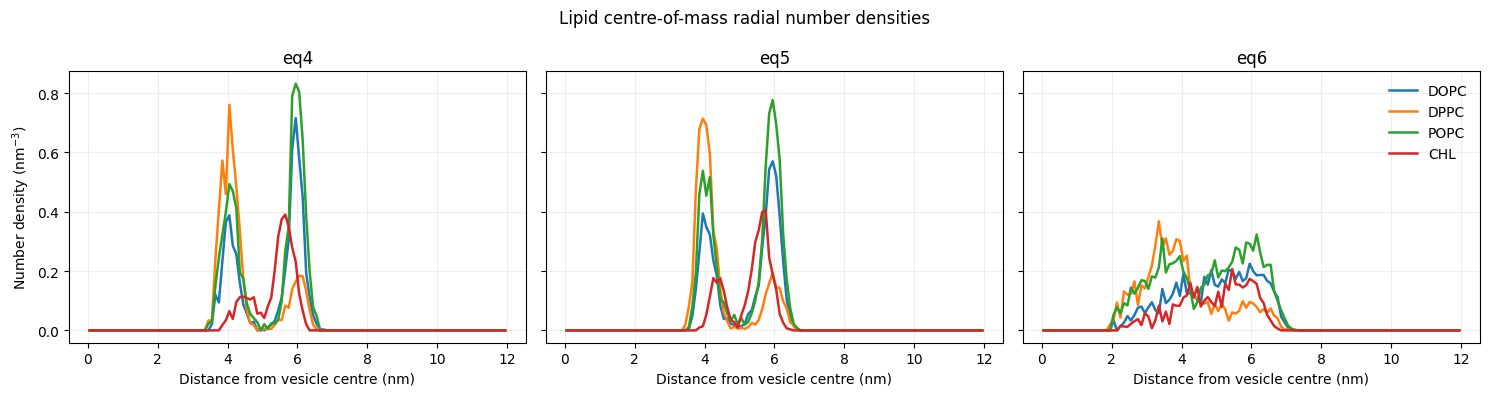

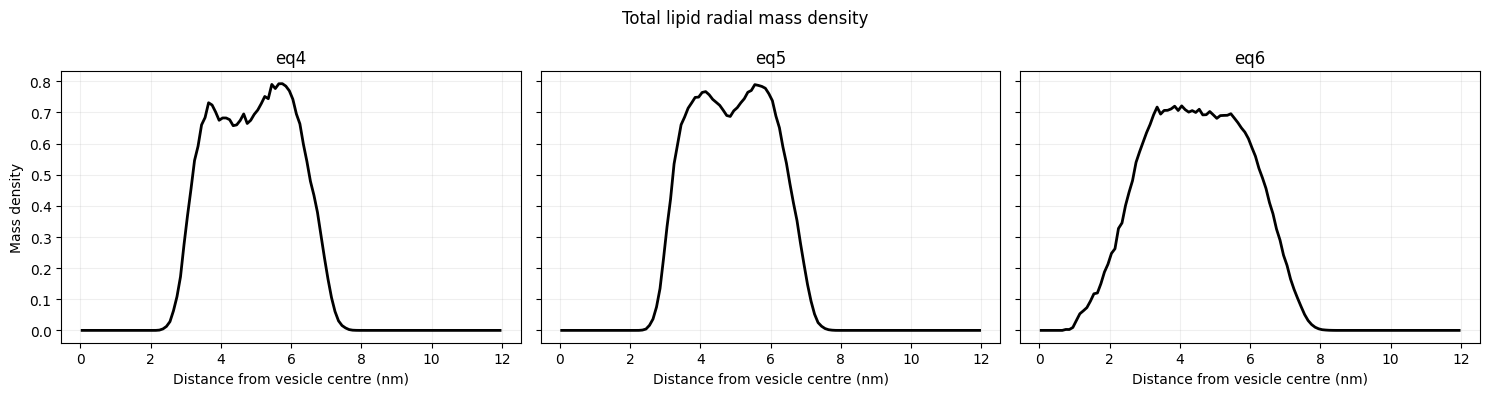

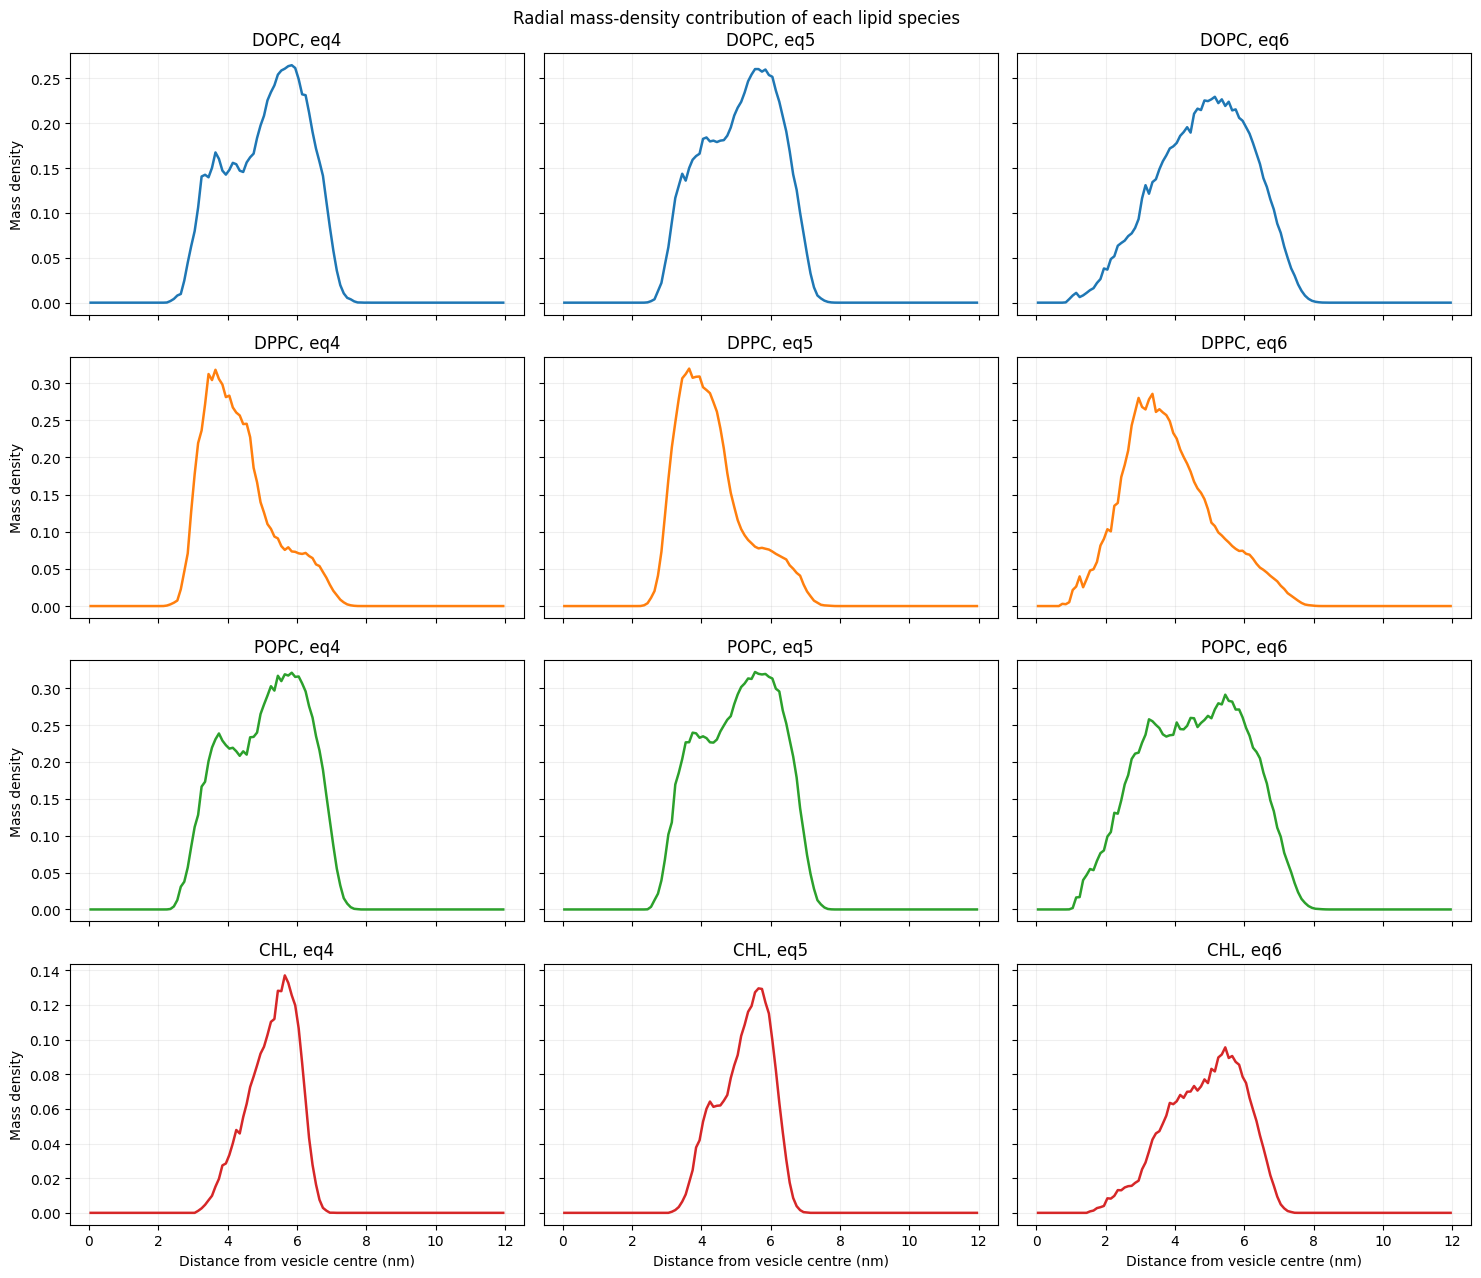

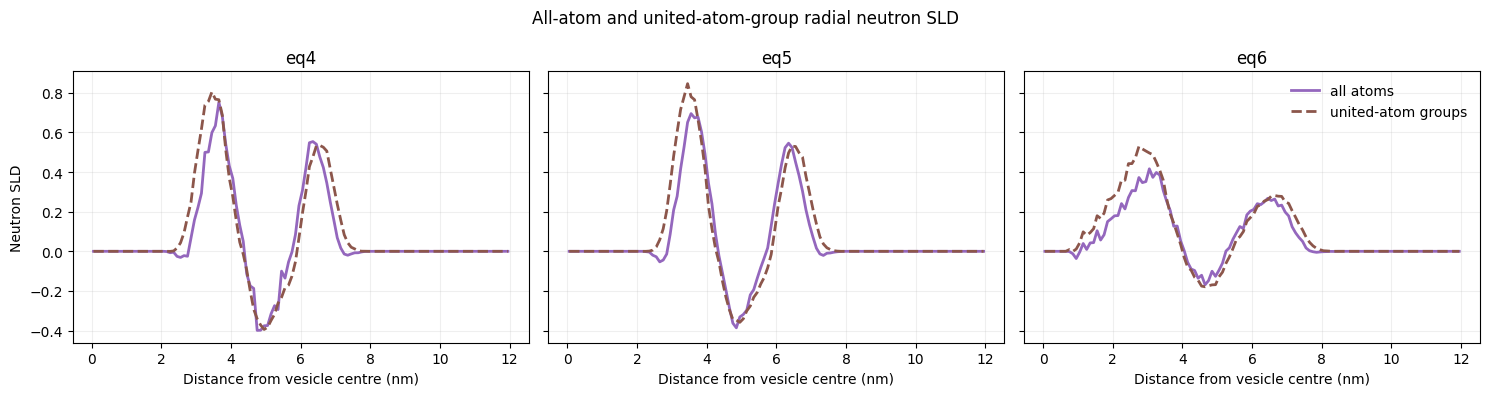

In [23]:
import matplotlib.pyplot as plt
import numpy as np

species_colours = {'DOPC': 'C0', 'DPPC': 'C1', 'POPC': 'C2', 'CHL': 'C3'}

def total_density(density_dir, density_type, contribution='ATOMS'):
    table = next(density_dir.glob(f'*_{density_type}_{contribution}_avr.dat'))
    return np.loadtxt(table).T

def species_mass_density(density_dir, residue):
    # Sum the C, H, N, O and P atomic mass-density contributions present
    # for this residue. CHL has no N or P tables, as expected.
    tables = sorted(density_dir.glob(f'*_mden_ATOM_*_{residue}_avr.dat'))
    if not tables:
        raise FileNotFoundError(f'no mass-density tables found for {residue}')
    profiles = [np.loadtxt(table) for table in tables]
    radius = profiles[0][:, 0]
    if not all(np.allclose(profile[:, 0], radius) for profile in profiles[1:]):
        raise ValueError(f'inconsistent radial grids for {residue}')
    return radius, sum(profile[:, 1] for profile in profiles)

number_figure, number_axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
mass_figure, mass_axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
species_figure, species_axes = plt.subplots(4, 3, figsize=(15, 13), sharex=True, sharey='row')
sld_figure, sld_axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)

for column, stage in enumerate((4, 5, 6)):
    analysis_dir = analysis_root / f'eq{stage}' / 'analysis'
    density_dir = analysis_dir / 'density'
    figures_dir = analysis_dir / 'figures'
    figures_dir.mkdir(exist_ok=True)

    stage_figure, stage_axis = plt.subplots(figsize=(7, 4.5))
    for residue in residues:
        table = next(density_dir.glob(f'*_nden_MCOM_{residue}_avr.dat'))
        radius, number_density = np.loadtxt(table).T
        number_axes[column].plot(radius, number_density, label=residue, color=species_colours[residue], linewidth=1.8)
        stage_axis.plot(radius, number_density, label=residue, color=species_colours[residue], linewidth=1.8)
    number_axes[column].set(title=f'eq{stage}', xlabel='Distance from vesicle centre (nm)')
    number_axes[column].grid(alpha=0.2)
    stage_axis.set(title=f'eq{stage}: lipid centre-of-mass number density', xlabel='Distance from vesicle centre (nm)', ylabel=r'Number density (nm$^{-3}$)')
    stage_axis.legend(frameon=False, ncol=2)
    stage_axis.grid(alpha=0.2)
    stage_figure.tight_layout()
    stage_figure.savefig(figures_dir / 'lipid_com_number_density.png', dpi=180)
    plt.close(stage_figure)

    radius, total_mass = total_density(density_dir, 'mden')
    mass_axes[column].plot(radius, total_mass, color='black', linewidth=2)
    mass_axes[column].set(title=f'eq{stage}', xlabel='Distance from vesicle centre (nm)')
    mass_axes[column].grid(alpha=0.2)
    stage_figure, stage_axis = plt.subplots(figsize=(7, 4.5))
    stage_axis.plot(radius, total_mass, color='black', linewidth=2)
    stage_axis.set(title=f'eq{stage}: total lipid mass density', xlabel='Distance from vesicle centre (nm)', ylabel='Mass density')
    stage_axis.grid(alpha=0.2)
    stage_figure.tight_layout()
    stage_figure.savefig(figures_dir / 'mass_density_total.png', dpi=180)
    plt.close(stage_figure)

    stage_figure, stage_axes = plt.subplots(2, 2, figsize=(10, 8), sharex=True)
    for row, residue in enumerate(residues):
        radius, residue_mass = species_mass_density(density_dir, residue)
        species_axis = species_axes[row, column]
        species_axis.plot(radius, residue_mass, color=species_colours[residue], linewidth=1.8)
        species_axis.set_title(f'{residue}, eq{stage}')
        species_axis.grid(alpha=0.2)
        if row == len(residues) - 1:
            species_axis.set_xlabel('Distance from vesicle centre (nm)')
        if column == 0:
            species_axis.set_ylabel('Mass density')
        stage_axis = stage_axes.flat[row]
        stage_axis.plot(radius, residue_mass, color=species_colours[residue], linewidth=1.8)
        stage_axis.set(title=residue, xlabel='Distance from vesicle centre (nm)', ylabel='Mass density')
        stage_axis.grid(alpha=0.2)
    stage_figure.suptitle(f'eq{stage}: mass-density contribution of each lipid species')
    stage_figure.tight_layout()
    stage_figure.savefig(figures_dir / 'mass_density_by_species.png', dpi=180)
    plt.close(stage_figure)

    radius, atom_sld = total_density(density_dir, 'nsld', 'ATOMS')
    uagr_radius, uagr_sld = total_density(density_dir, 'nsld', 'UAGRS')
    if not np.allclose(uagr_radius, radius):
        raise ValueError(f'inconsistent ATOMS/UAGRS SLD grids for eq{stage}')
    sld_axes[column].plot(radius, atom_sld, label='all atoms', color='C4', linewidth=2)
    sld_axes[column].plot(radius, uagr_sld, label='united-atom groups', color='C5', linestyle='--', linewidth=2)
    sld_axes[column].set(title=f'eq{stage}', xlabel='Distance from vesicle centre (nm)')
    sld_axes[column].grid(alpha=0.2)
    stage_figure, stage_axis = plt.subplots(figsize=(7, 4.5))
    stage_axis.plot(radius, atom_sld, label='all atoms', color='C4', linewidth=2)
    stage_axis.plot(radius, uagr_sld, label='united-atom groups', color='C5', linestyle='--', linewidth=2)
    stage_axis.set(title=f'eq{stage}: all-atom and united-atom-group neutron SLD', xlabel='Distance from vesicle centre (nm)', ylabel='Neutron SLD')
    stage_axis.legend(frameon=False)
    stage_axis.grid(alpha=0.2)
    stage_figure.tight_layout()
    stage_figure.savefig(figures_dir / 'neutron_sld_total.png', dpi=180)
    plt.close(stage_figure)

number_axes[0].set_ylabel(r'Number density (nm$^{-3}$)')
number_axes[-1].legend(frameon=False)
number_figure.suptitle('Lipid centre-of-mass radial number densities')
number_figure.tight_layout()
mass_axes[0].set_ylabel('Mass density')
mass_figure.suptitle('Total lipid radial mass density')
mass_figure.tight_layout()
species_figure.suptitle('Radial mass-density contribution of each lipid species')
species_figure.tight_layout()
sld_axes[0].set_ylabel('Neutron SLD')
sld_axes[-1].legend(frameon=False)
sld_figure.suptitle('All-atom and united-atom-group radial neutron SLD')
sld_figure.tight_layout()
plt.show()

### Mixed-lipid clusters

The subcluster selection contains DOPC, DPPC, POPC and CHL together. The first plot follows the size of the largest mixed-lipid cluster in each leaflet from frame to frame. The second is the time-averaged population of each mixed-lipid cluster size. Corresponding full-size plots are saved under each stage's `analysis/figures/` directory.

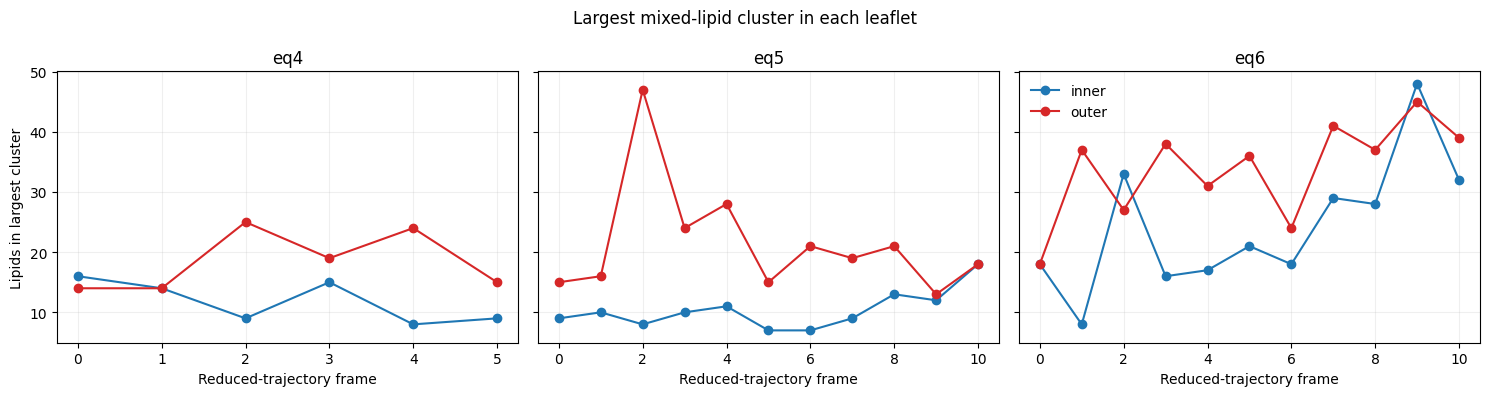

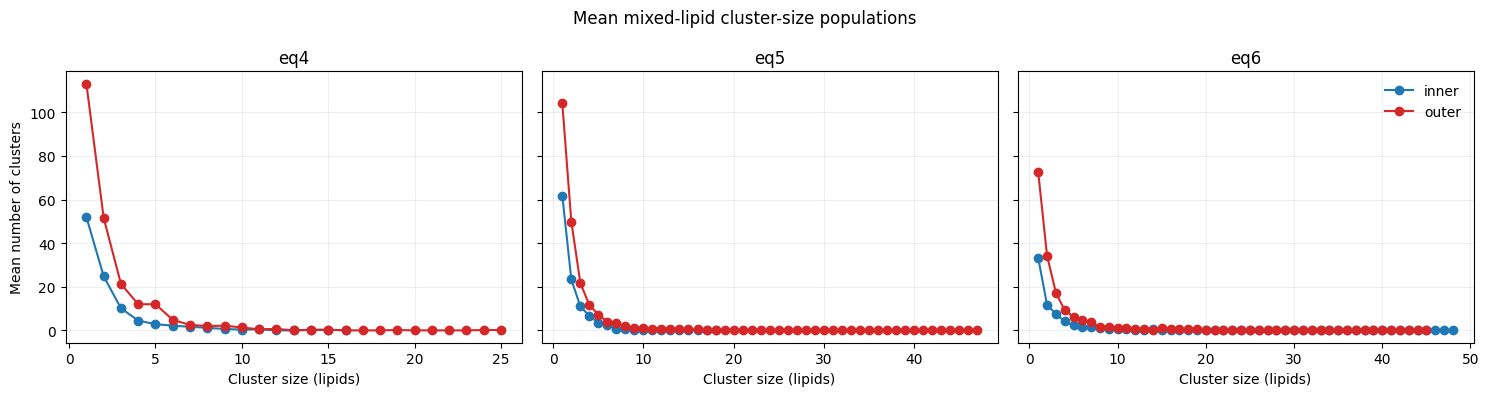

In [24]:
leaflets = {'int': ('inner', 'C0'), 'ext': ('outer', 'C3')}
evolution_figure, evolution_axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
population_figure, population_axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for stage, evolution_axis, population_axis in zip((4, 5, 6), evolution_axes, population_axes):
    analysis_dir = analysis_root / f'eq{stage}' / 'analysis'
    cluster_dir = analysis_dir / 'cluster-all-lipids-dmax1.6-0.8nm'
    figures_dir = analysis_dir / 'figures'
    figures_dir.mkdir(exist_ok=True)
    stage_evolution, stage_evolution_axis = plt.subplots(figsize=(7, 4.5))
    stage_population, stage_population_axis = plt.subplots(figsize=(7, 4.5))

    for leaflet, (label, colour) in leaflets.items():
        evolution_table = next(cluster_dir.glob(f'*_xcls_{leaflet}_DOPC_DPPC_POPC_CHL_evol.dat'))
        evolution = np.loadtxt(evolution_table, comments='#', ndmin=2)
        for axis in (evolution_axis, stage_evolution_axis):
            axis.plot(evolution[:, 0], evolution[:, 1], marker='o', label=label, color=colour)

        population_table = next(cluster_dir.glob(f'*_hcls_{leaflet}_DOPC_DPPC_POPC_CHL_avr.dat'))
        population = np.loadtxt(population_table, ndmin=2)
        population = population[population[:, 0] > 0]
        for axis in (population_axis, stage_population_axis):
            axis.plot(population[:, 0], population[:, 1], marker='o', label=label, color=colour)

    evolution_axis.set_title(f'eq{stage}')
    evolution_axis.set_xlabel('Reduced-trajectory frame')
    evolution_axis.grid(alpha=0.2)
    population_axis.set_title(f'eq{stage}')
    population_axis.set_xlabel('Cluster size (lipids)')
    population_axis.grid(alpha=0.2)

    stage_evolution_axis.set(title=f'eq{stage}: largest mixed-lipid cluster', xlabel='Reduced-trajectory frame', ylabel='Lipids in largest cluster')
    stage_evolution_axis.legend(frameon=False)
    stage_evolution_axis.grid(alpha=0.2)
    stage_evolution.tight_layout()
    stage_evolution.savefig(figures_dir / 'all_lipids_largest_cluster_evolution.png', dpi=180)
    plt.close(stage_evolution)

    stage_population_axis.set(title=f'eq{stage}: mean mixed-lipid cluster-size population', xlabel='Cluster size (lipids)', ylabel='Mean number of clusters')
    stage_population_axis.legend(frameon=False)
    stage_population_axis.grid(alpha=0.2)
    stage_population.tight_layout()
    stage_population.savefig(figures_dir / 'all_lipids_cluster_size_population.png', dpi=180)
    plt.close(stage_population)

evolution_axes[0].set_ylabel('Lipids in largest cluster')
evolution_axes[-1].legend(frameon=False)
evolution_figure.suptitle('Largest mixed-lipid cluster in each leaflet')
evolution_figure.tight_layout()
population_axes[0].set_ylabel('Mean number of clusters')
population_axes[-1].legend(frameon=False)
population_figure.suptitle('Mean mixed-lipid cluster-size populations')
population_figure.tight_layout()
plt.show()

The density and clustering curves change across the three restrained equilibration stages, but they should be interpreted cautiously: the supplied `eq4` trajectory contains only 6 retained frames and `eq5` and `eq6` contain 11 each. These reduced trajectories are appropriate for learning and checking the analysis workflow, not for estimating converged equilibrium distributions or uncertainties. For a scientific analysis, repeat the same procedure on a sufficiently long production trajectory and assess convergence and sampling.